In [21]:
!pip install yfinance
import yfinance as yf
data = yf.download("SPY", start="2005-01-01", auto_adjust=True)
data.to_csv("spy.csv")

[*********************100%***********************]  1 of 1 completed


                 Close        MA50       MA200
Date                                          
2026-10-12  778.099976  766.942061  720.135188
2026-10-13  778.010010  767.386396  720.600091
2026-10-14  769.599976  767.390009  721.023291
2026-10-15  771.789978  767.468145  721.469645
2026-10-16  763.250000  767.400020  721.877467


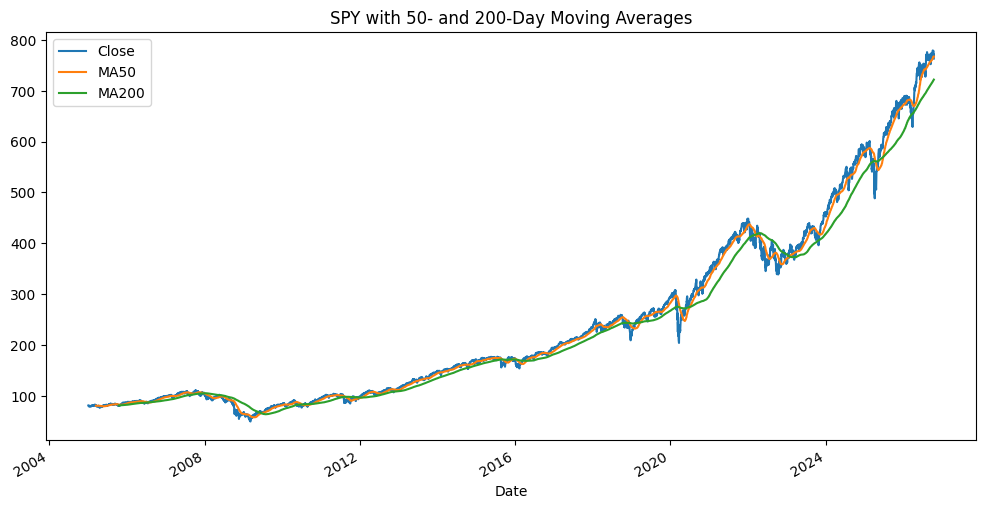

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Grab the closing prices as a simple column
close = data["Close"].squeeze()

# Build a clean table to work in
df = pd.DataFrame({"Close": close})

# Calculate the 50-day and 200-day moving averages
df["MA50"] = df["Close"].rolling(50).mean()
df["MA200"] = df["Close"].rolling(200).mean()

# Look at the last few rows
print(df.tail())

# Plot price with both moving averages
df[["Close", "MA50", "MA200"]].plot(figsize=(12, 6), title="SPY with 50- and 200-Day Moving Averages")
plt.show()

Buy & Hold final value: $ 94395.62
Strategy final value:   $ 64039.91
Number of trades: 21


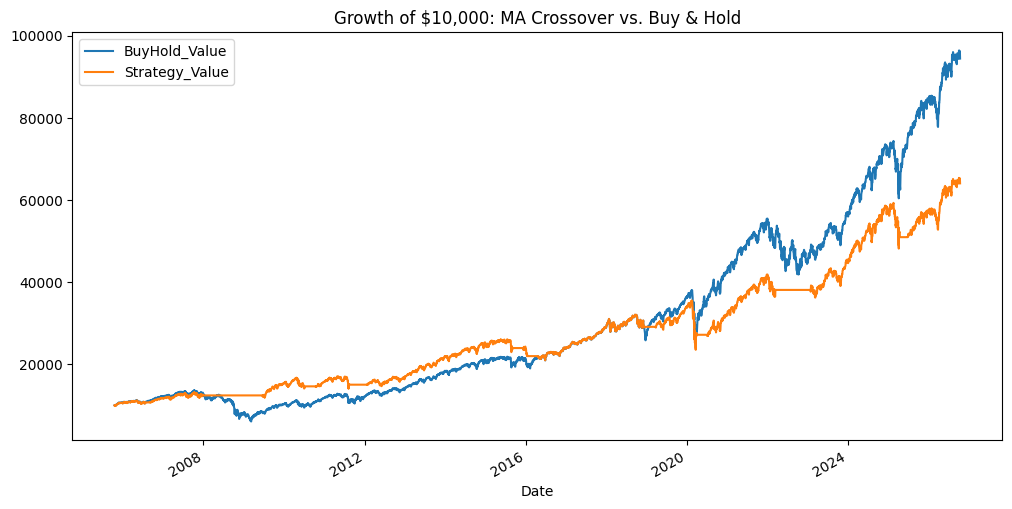

In [23]:
# 1 = invested, 0 = in cash
df["Signal"] = (df["MA50"] > df["MA200"]).astype(int)

# Act the NEXT day (you can't trade on a signal until the day closes)
df["Position"] = df["Signal"].shift(1).fillna(0)

# Daily returns of SPY
df["Market_Return"] = df["Close"].pct_change()

# Count trades and subtract a 0.1% cost each time we buy or sell
df["Trades"] = df["Position"].diff().abs().fillna(0)
cost = 0.001
df["Strategy_Return"] = df["Position"] * df["Market_Return"] - df["Trades"] * cost

# Start both strategies on the same day (once the 200-day average exists)
df = df.dropna()

# Growth of $10,000
df["BuyHold_Value"] = 10000 * (1 + df["Market_Return"]).cumprod()
df["Strategy_Value"] = 10000 * (1 + df["Strategy_Return"]).cumprod()

print("Buy & Hold final value: $", round(df["BuyHold_Value"].iloc[-1], 2))
print("Strategy final value:   $", round(df["Strategy_Value"].iloc[-1], 2))
print("Number of trades:", int(df["Trades"].sum()))

df[["BuyHold_Value", "Strategy_Value"]].plot(figsize=(12, 6), title="Growth of $10,000: MA Crossover vs. Buy & Hold")
plt.show()

In [24]:
import numpy as np

def metrics(returns, values):
    years = len(returns) / 252                      # ~252 trading days per year
    cagr = (values.iloc[-1] / 10000) ** (1 / years) - 1
    vol = returns.std() * np.sqrt(252)
    sharpe = (returns.mean() / returns.std()) * np.sqrt(252)
    max_dd = (values / values.cummax() - 1).min()
    return [f"{cagr:.2%}", f"{vol:.2%}", f"{sharpe:.2f}", f"{max_dd:.2%}"]

results = pd.DataFrame({
    "Buy & Hold": metrics(df["Market_Return"], df["BuyHold_Value"]),
    "MA Crossover": metrics(df["Strategy_Return"], df["Strategy_Value"]),
}, index=["Annualized Return", "Volatility", "Sharpe Ratio", "Max Drawdown"])

print(results)
print(f"\nTime invested: {df['Position'].mean():.1%}")

                  Buy & Hold MA Crossover
Annualized Return     11.30%        9.26%
Volatility            19.11%       13.80%
Sharpe Ratio            0.66         0.71
Max Drawdown         -55.19%      -33.72%

Time invested: 79.0%


In [25]:
def period_results(start, end):
    sub = df.loc[start:end]
    bh_vals = 10000 * (1 + sub["Market_Return"]).cumprod()
    st_vals = 10000 * (1 + sub["Strategy_Return"]).cumprod()
    return pd.DataFrame({
        "Buy & Hold": metrics(sub["Market_Return"], bh_vals),
        "MA Crossover": metrics(sub["Strategy_Return"], st_vals),
    }, index=["Annualized Return", "Volatility", "Sharpe Ratio", "Max Drawdown"])

print("=== 2005-2015 ===")
print(period_results("2005-01-01", "2015-12-31"))
print("\n=== 2016-2026 ===")
print(period_results("2016-01-01", "2026-12-31"))

=== 2005-2015 ===
                  Buy & Hold MA Crossover
Annualized Return      7.65%        8.93%
Volatility            20.51%       12.47%
Sharpe Ratio            0.46         0.75
Max Drawdown         -55.19%      -17.31%

=== 2016-2026 ===
                  Buy & Hold MA Crossover
Annualized Return     14.88%        9.58%
Volatility            17.69%       14.96%
Sharpe Ratio            0.87         0.69
Max Drawdown         -33.72%      -33.72%


In [26]:
# Get the 13-week Treasury bill yield (annual %, so convert to a daily rate)
rf = yf.download("^IRX", start="2005-01-01")["Close"].squeeze()
df["RF"] = (rf / 100 / 252).reindex(df.index).ffill().fillna(0)

# Strategy now earns T-bill interest when it's in cash
df["Strategy_Return"] = (df["Position"] * df["Market_Return"]
                         + (1 - df["Position"]) * df["RF"]
                         - df["Trades"] * cost)
df["Strategy_Value"] = 10000 * (1 + df["Strategy_Return"]).cumprod()

# Updated metrics: Sharpe ratio now uses returns ABOVE the risk-free rate
def metrics(returns, values):
    rf_period = df["RF"].loc[returns.index]
    excess = returns - rf_period
    years = len(returns) / 252
    cagr = (values.iloc[-1] / 10000) ** (1 / years) - 1
    vol = returns.std() * np.sqrt(252)
    sharpe = (excess.mean() / excess.std()) * np.sqrt(252)
    max_dd = (values / values.cummax() - 1).min()
    return [f"{cagr:.2%}", f"{vol:.2%}", f"{sharpe:.2f}", f"{max_dd:.2%}"]

print("=== Full period ===")
print(period_results("2005-01-01", "2026-12-31"))
print("\n=== 2005-2015 ===")
print(period_results("2005-01-01", "2015-12-31"))
print("\n=== 2016-2026 ===")
print(period_results("2016-01-01", "2026-12-31"))

/tmp/ipykernel_2348/3700023318.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  rf = yf.download("^IRX", start="2005-01-01")["Close"].squeeze()
[*********************100%***********************]  1 of 1 completed

=== Full period ===
                  Buy & Hold MA Crossover
Annualized Return     11.30%        9.57%
Volatility            19.11%       13.80%
Sharpe Ratio            0.57         0.61
Max Drawdown         -55.19%      -33.72%

=== 2005-2015 ===
                  Buy & Hold MA Crossover
Annualized Return      7.65%        9.14%
Volatility            20.51%       12.47%
Sharpe Ratio            0.41         0.67
Max Drawdown         -55.19%      -17.31%

=== 2016-2026 ===
                  Buy & Hold MA Crossover
Annualized Return     14.88%        9.97%
Volatility            17.69%       14.96%
Sharpe Ratio            0.74         0.56
Max Drawdown         -33.72%      -33.72%


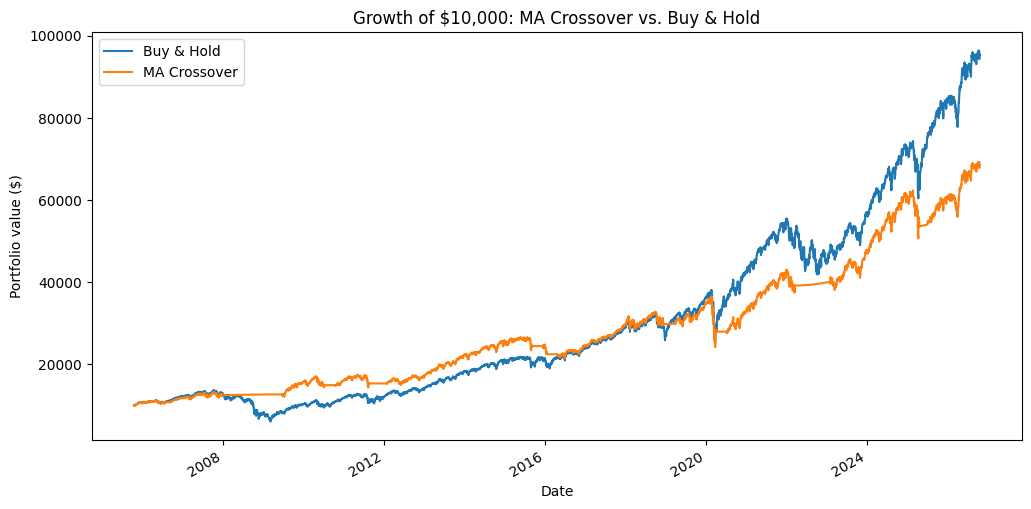

In [27]:
ax = df[["BuyHold_Value", "Strategy_Value"]].rename(
    columns={"BuyHold_Value": "Buy & Hold", "Strategy_Value": "MA Crossover"}
).plot(figsize=(12, 6), title="Growth of $10,000: MA Crossover vs. Buy & Hold")
ax.set_ylabel("Portfolio value ($)")
plt.savefig("growth.png", dpi=150, bbox_inches="tight")
plt.show()

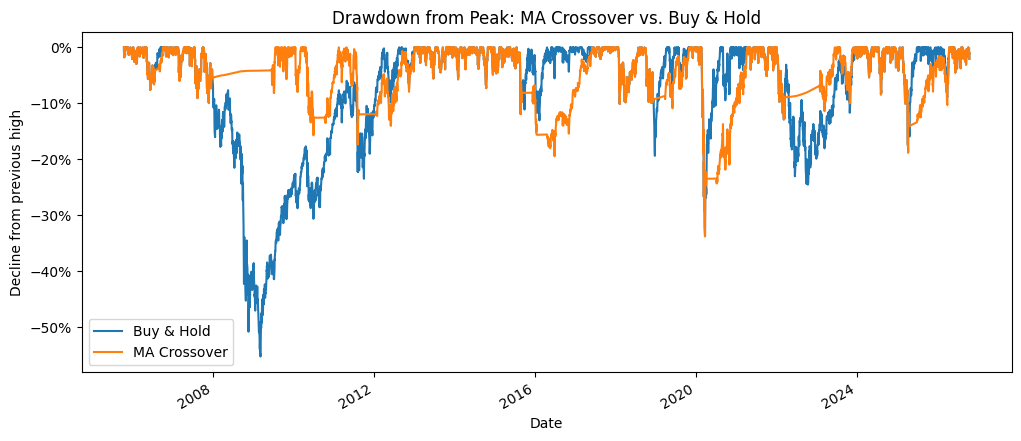

In [28]:
import matplotlib.ticker as mtick

dd = pd.DataFrame({
    "Buy & Hold": df["BuyHold_Value"] / df["BuyHold_Value"].cummax() - 1,
    "MA Crossover": df["Strategy_Value"] / df["Strategy_Value"].cummax() - 1,
})

ax = dd.plot(figsize=(12, 5), title="Drawdown from Peak: MA Crossover vs. Buy & Hold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylabel("Decline from previous high")
plt.savefig("drawdown.png", dpi=150, bbox_inches="tight")
plt.show()